In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load database credentials from the .env file
load_dotenv()

# Check that all required variables are available
required_variables = [
    "DB_USER",
    "DB_PASSWORD",
    "DB_HOST",
    "DB_PORT",
    "DB_NAME"
]

missing_variables = [
    variable for variable in required_variables
    if not os.getenv(variable)
]

if missing_variables:
    raise ValueError(
        f"Missing environment variables: {missing_variables}"
    )

# Database schema
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

# Validate schema name
if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", schema):
    raise ValueError("Invalid database schema name.")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={
        "options": "-c default_transaction_read_only=on"
    }
)

# Test connection
with engine.connect() as connection:
    database_info = connection.execute(
        text("""
            SELECT
                current_database() AS database_name,
                current_user AS database_user,
                version() AS postgresql_version
        """)
    ).fetchone()

print("PostgreSQL connection successful!")
print("Database:", database_info.database_name)
print("User:", database_info.database_user)
print("Schema:", schema)
print("Version:", database_info.postgresql_version)

PostgreSQL connection successful!
Database: nf_da_onl_en_200726
User: atikesanli
Schema: s_atikesanli
Version: PostgreSQL 17.9 on x86_64-pc-linux-gnu, compiled by x86_64-pc-linux-gnu-gcc (GCC) 12.4.0, 64-bit


In [4]:
rq6_columns_query = text(f"""
    SELECT
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = '{schema}'
      AND table_name = 'mart_acquired_seller_performance'
    ORDER BY ordinal_position
""")

with engine.connect() as connection:
    rq6_columns = pd.read_sql_query(
        rq6_columns_query, connection
    )

display(rq6_columns)

,column_name,data_type
0,seller_id,character varying
1,mql_id,character varying
2,business_segment,text
3,won_date,timestamp without time zone
4,seller_matching_status,text
5,total_marketplace_orders,bigint
6,total_product_value,real
7,total_items_sold,numeric
8,eligible_delivered_orders,bigint
9,average_review_score,numeric


In [5]:
rq6_query = text(f"""
    SELECT *
    FROM {schema}.mart_acquired_seller_performance
""")

with engine.connect() as connection:
    rq6_df = pd.read_sql_query(rq6_query, connection)

print("Dataset shape:", rq6_df.shape)
print("Unique sellers:", rq6_df["seller_id"].nunique())
print("Duplicate seller IDs:", rq6_df["seller_id"].duplicated().sum())

display(rq6_df.head(10))

Dataset shape: (842, 13)
Unique sellers: 842
Duplicate seller IDs: 0


,seller_id,mql_id,business_segment,won_date,seller_matching_status,total_marketplace_orders,total_product_value,total_items_sold,eligible_delivered_orders,average_review_score,average_freight_per_seller_order,late_delivery_rate,average_delivery_days
0,00065220becb8785e2cf78355eb9bf68,00dc5000951c268cc8655294daf67b1b,handcrafted,2018-07-10 11:34:50,Unmatched,0,0.000,0.000,0,NaN,NaN,NaN,NaN
1,01266d4c46afa519678d16a8b683d325,ae437864746ae2a9e694a6ed2b5824db,construction_tools_house_garden,2018-05-18 20:02:04,Matched,3,90.250,3.000,3,5.000,15.740,0.000,5.920
2,013d100f608a64ec8275c038aedeb064,f7066703eb3987f21f0d102ea8caaeb5,food_supplement,2018-04-06 14:15:21,Unmatched,0,0.000,0.000,0,NaN,NaN,NaN,NaN
3,01fd077212124329bac32490e8ef80d9,180d9ac0990bb42907fe9cc7aa3eb5a1,household_utilities,2018-03-28 22:45:45,Matched,31,1208.000,39.000,31,4.160,18.560,3.230,8.150
4,0255dc67cb6bad298606136951ab1877,4388a23da67b154b780b78dd7ea4636e,computers,2018-03-06 18:49:03,Unmatched,0,0.000,0.000,0,NaN,NaN,NaN,NaN
5,026c6180cd86d6069dad573ce69b465e,f88920d4589dae7abec2eb05fca153e3,household_utilities,2018-10-03 12:28:55,Unmatched,0,0.000,0.000,0,NaN,NaN,NaN,NaN
6,02df983480ff75ead8a031a3c7a849ad,ac894bcbadb0692e692ba49e19bc219b,phone_mobile,2018-04-18 19:05:58,Unmatched,0,0.000,0.000,0,NaN,NaN,NaN,NaN
7,02f623a8eb246f3c5f7c2f96462654e6,ffdd99e05df27c02a2fb1669d49e0c76,sports_leisure,2018-04-18 20:16:19,Matched,44,6378.000,44.000,42,4.600,18.430,9.520,8.530
8,03a2a6dcbe45d639c4dc2a0d24769c40,586e57a7ef16035bd85e2dcf44248130,construction_tools_house_garden,2018-02-09 18:11:10,Matched,9,1078.410,9.000,9,4.110,19.140,11.110,10.450
9,044668ccd5316b12a7cf0d54a156e3e9,5985e72b3752e4749926885db1b45be4,food_drink,2018-01-31 21:00:13,Matched,3,137.800,4.000,3,5.000,17.850,0.000,7.850


In [6]:
print("Total acquired sellers:", len(rq6_df))
print("Unique seller IDs:", rq6_df["seller_id"].nunique())
print("Duplicate seller IDs:", rq6_df["seller_id"].duplicated().sum())

matching_summary = (
    rq6_df.groupby("seller_matching_status")
    .agg(
        number_of_sellers=("seller_id", "nunique"),
        total_marketplace_orders=("total_marketplace_orders", "sum")
    )
    .reset_index()
)

matching_summary["percentage"] = (
    matching_summary["number_of_sellers"]
    / rq6_df["seller_id"].nunique() * 100
)

display(matching_summary.round(2))

Total acquired sellers: 842
Unique seller IDs: 842
Duplicate seller IDs: 0


,seller_matching_status,number_of_sellers,total_marketplace_orders,percentage
0,Matched,380,4518,45.130
1,Unmatched,462,0,54.870


In [7]:
matched_sellers = rq6_df[
    rq6_df["seller_matching_status"] == "Matched"
].copy()

activity_summary = pd.DataFrame({
    "Metric": [
        "Matched sellers",
        "Total marketplace orders",
        "Total product value",
        "Total items sold",
        "Eligible delivered orders",
        "Average orders per seller",
        "Average customer review score",
        "Average delivery days",
        "Late delivery rate"
    ],
    "Value": [
        len(matched_sellers),
        matched_sellers["total_marketplace_orders"].sum(),
        matched_sellers["total_product_value"].sum(),
        matched_sellers["total_items_sold"].sum(),
        matched_sellers["eligible_delivered_orders"].sum(),
        matched_sellers["total_marketplace_orders"].mean(),
        matched_sellers["average_review_score"].mean(),
        matched_sellers["average_delivery_days"].mean(),
        matched_sellers["late_delivery_rate"].mean()
    ]
})

display(activity_summary.round(2))

,Metric,Value
0,Matched sellers,380.000
1,Total marketplace orders,4518.000
2,Total product value,676851.460
3,Total items sold,5044.000
4,Eligible delivered orders,4405.000
5,Average orders per seller,11.890
6,Average customer review score,4.340
7,Average delivery days,8.940
8,Late delivery rate,6.770


In [8]:
segment_summary = (
    matched_sellers.groupby("business_segment", dropna=False)
    .agg(
        number_of_sellers=("seller_id", "nunique"),
        total_orders=("total_marketplace_orders", "sum"),
        average_review_score=("average_review_score", "mean"),
        average_late_delivery_rate=("late_delivery_rate", "mean"),
        average_delivery_days=("average_delivery_days", "mean")
    )
    .reset_index()
    .sort_values("number_of_sellers", ascending=False)
)

display(segment_summary.round(2))

,business_segment,number_of_sellers,total_orders,average_review_score,average_late_delivery_rate,average_delivery_days
15,health_beauty,45,705,4.580,4.870,8.750
19,household_utilities,44,502,4.480,5.200,8.560
17,home_decor,44,361,4.290,13.780,9.170
8,construction_tools_house_garden,32,271,4.330,11.720,9.030
1,audio_video_electronics,31,249,4.080,5.310,8.690
6,car_accessories,30,148,4.040,8.490,8.460
22,pet,17,247,4.360,4.880,8.280
3,bags_backpacks,14,135,4.620,4.510,9.250
25,sports_leisure,14,167,4.700,1.620,7.560
7,computers,12,106,4.450,1.240,9.980


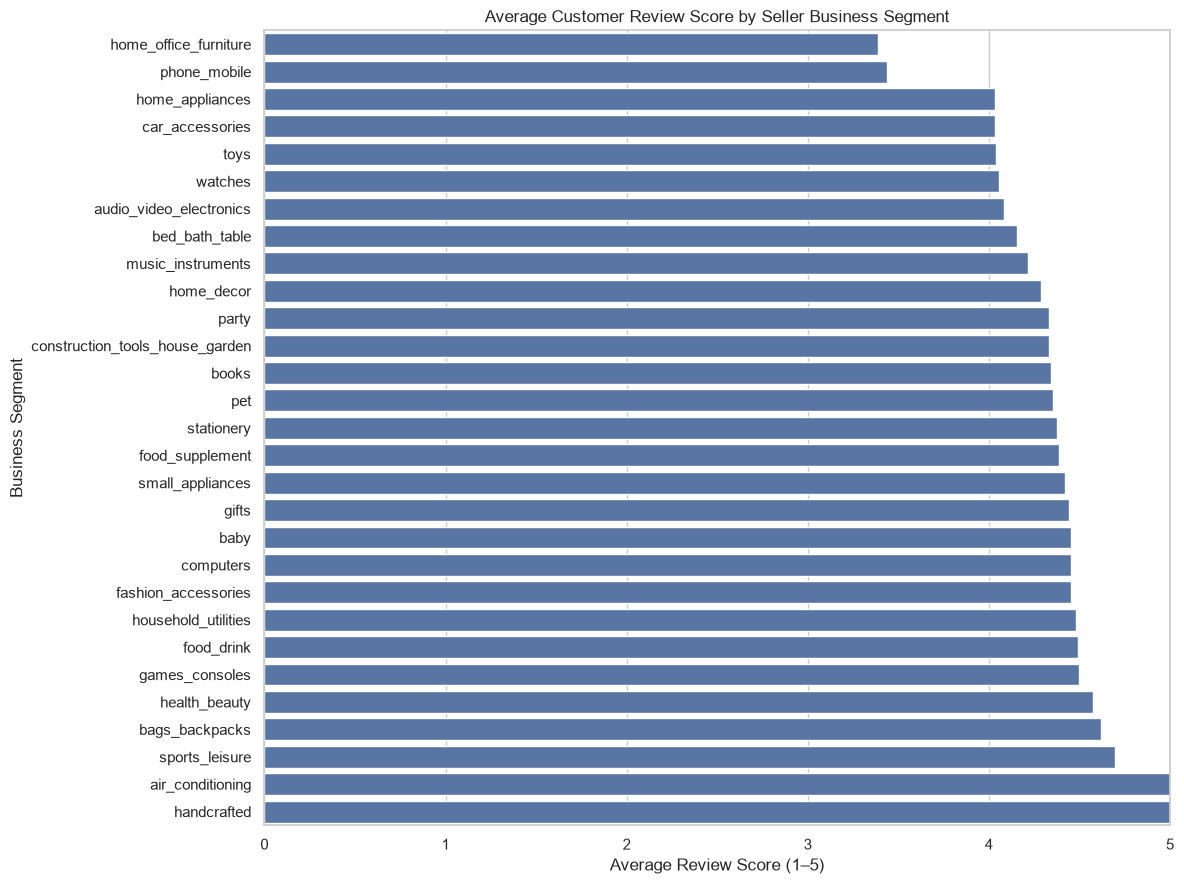

In [9]:
plt.figure(figsize=(12, 9))

segment_plot = segment_summary.sort_values(
    "average_review_score", ascending=True
)

sns.barplot(
    data=segment_plot,
    x="average_review_score",
    y="business_segment"
)

plt.title("Average Customer Review Score by Seller Business Segment")
plt.xlabel("Average Review Score (1–5)")
plt.ylabel("Business Segment")
plt.xlim(0, 5)

plt.tight_layout()
plt.savefig(
    "../figures/rq6_review_score_by_business_segment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

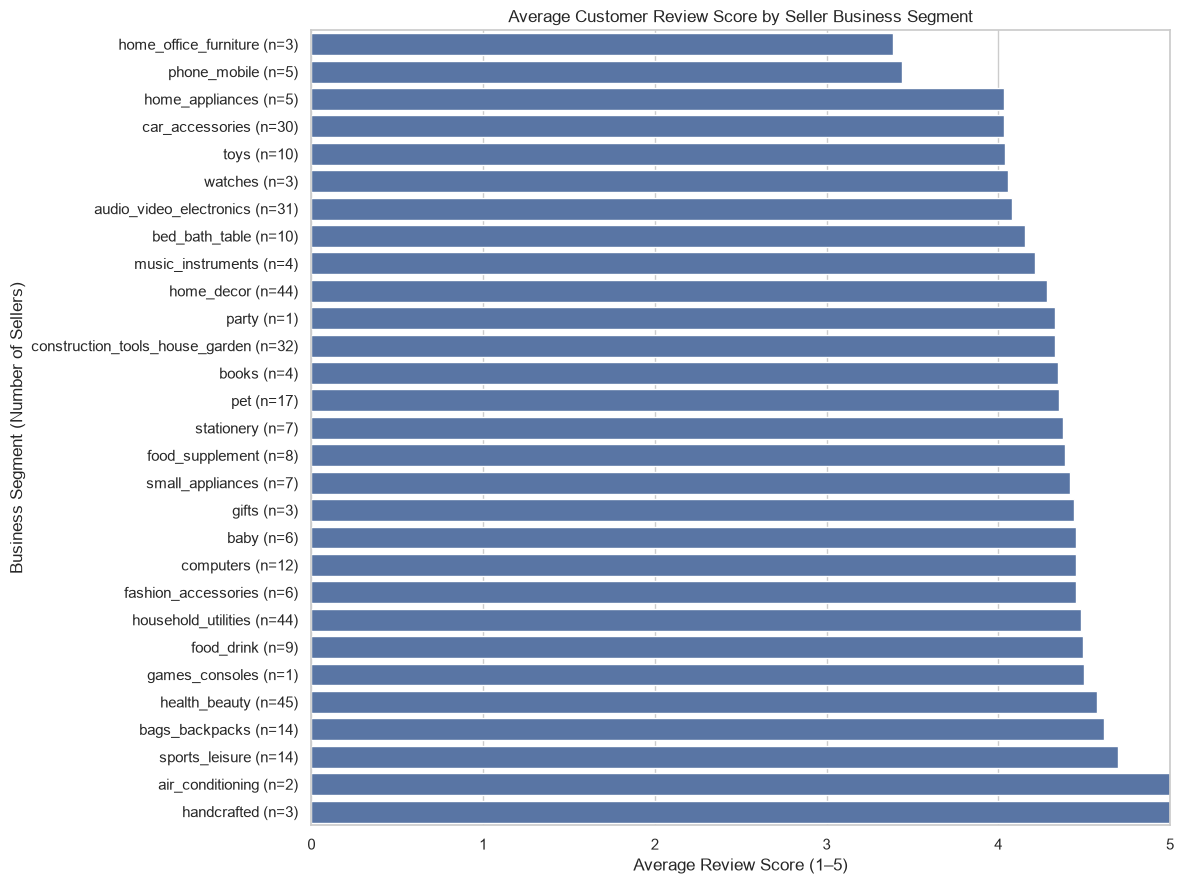

In [10]:
plt.figure(figsize=(12, 9))

segment_plot = segment_summary.sort_values(
    "average_review_score", ascending=True
).copy()

segment_plot["segment_label"] = (
    segment_plot["business_segment"]
    + " (n="
    + segment_plot["number_of_sellers"].astype(str)
    + ")"
)

sns.barplot(
    data=segment_plot,
    x="average_review_score",
    y="segment_label"
)

plt.title("Average Customer Review Score by Seller Business Segment")
plt.xlabel("Average Review Score (1–5)")
plt.ylabel("Business Segment (Number of Sellers)")
plt.xlim(0, 5)
plt.tight_layout()

plt.savefig(
    "../figures/rq6_review_score_by_business_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Check the number of matched sellers with available performance data

performance_data_check = matched_sellers[
    [
        "average_review_score",
        "average_delivery_days",
        "late_delivery_rate"
    ]
].count()

print("Matched sellers:", len(matched_sellers))
print("\nSellers with available performance data:")
print(performance_data_check)

print("\nMissing values:")
print(
    matched_sellers[
        [
            "average_review_score",
            "average_delivery_days",
            "late_delivery_rate"
        ]
    ].isna().sum()
)

Matched sellers: 380

Sellers with available performance data:
average_review_score     376
average_delivery_days    376
late_delivery_rate       376
dtype: int64

Missing values:
average_review_score     4
average_delivery_days    4
late_delivery_rate       4
dtype: int64


In [12]:
# Calculate order-weighted performance measures

metrics = [
    "average_review_score",
    "average_delivery_days",
    "late_delivery_rate"
]

for metric in metrics:
    valid_data = matched_sellers[
        matched_sellers[metric].notna()
        & matched_sellers["eligible_delivered_orders"].notna()
        & (matched_sellers["eligible_delivered_orders"] > 0)
    ]

    weighted_average = np.average(
        valid_data[metric],
        weights=valid_data["eligible_delivered_orders"]
    )

    print(f"{metric}:")
    print(f"  Sellers included: {len(valid_data)}")
    print(f"  Eligible delivered orders: "
          f"{valid_data['eligible_delivered_orders'].sum()}")
    print(f"  Order-weighted average: {weighted_average:.3f}")
    print()

average_review_score:
  Sellers included: 376
  Eligible delivered orders: 4405
  Order-weighted average: 4.280

average_delivery_days:
  Sellers included: 376
  Eligible delivered orders: 4405
  Order-weighted average: 9.789

late_delivery_rate:
  Sellers included: 376
  Eligible delivered orders: 4405
  Order-weighted average: 7.242



### RQ6: Marketplace Performance of Acquired Sellers

The sixth research question investigated the marketplace performance of sellers acquired through the Olist marketing funnel, focusing on sales activity, customer satisfaction and delivery performance.

The analysis included 842 acquired sellers recorded in the marketing funnel dataset. Of these, 380 sellers (45.13%) could be successfully matched to marketplace seller records, while 462 sellers (54.87%) could not be matched. The matched sellers generated a total of 4,518 marketplace orders, comprising 5,044 items sold and a total product value of approximately R$676,851.46.

Among the matched sellers, 376 had available customer satisfaction and delivery performance data. These sellers accounted for 4,405 eligible delivered orders. Using an order-weighted approach, the average customer review score was 4.28 on a five-point scale. The average delivery duration was 9.79 days, while the weighted late delivery rate was 7.24%. Overall, these findings indicate generally positive customer satisfaction and relatively reliable delivery performance among the acquired sellers that could be linked to marketplace activity.

Further analysis examined differences in customer satisfaction across seller business segments. Sports and leisure recorded one of the highest average review scores (4.70), followed by bags and backpacks (4.62) and health and beauty (4.58). Health and beauty was particularly notable because it represented 45 matched sellers and 705 marketplace orders. In contrast, home office furniture recorded the lowest average review score (3.39), followed by phone and mobile (3.44). However, these lower averages were based on only three and five sellers, respectively, and should therefore be interpreted cautiously.

Differences were also observed in delivery performance across business segments. Sports and leisure recorded a relatively low average late delivery rate of 1.62%, whereas home decor recorded 13.78%. The watches segment had a late delivery rate of 16.84%, although this result was based on only three sellers. These findings indicate that customer satisfaction and delivery reliability vary across the business segments represented by acquired sellers.

Overall, the results suggest that sellers acquired through the Olist marketing funnel demonstrated positive marketplace performance in terms of customer satisfaction and delivery reliability. Nevertheless, the analysis also revealed differences between business segments and limitations in matching acquired sellers to marketplace records. The unmatched sellers could not be evaluated in terms of marketplace activity, and the results therefore represent only the matched subset of acquired sellers. Furthermore, the analysis is descriptive and does not establish that marketing acquisition caused subsequent seller performance.

The findings of RQ6 provide descriptive support for the alternative hypothesis (H1), indicating that sellers acquired through the Olist marketing funnel demonstrated generally positive marketplace performance in terms of customer satisfaction and delivery reliability. The order-weighted average customer review score was 4.28 out of 5, while the average delivery duration was 9.79 days and the late delivery rate was 7.24%.

However, marketplace performance varied across business segments, and only 380 of the 842 acquired sellers could be matched to marketplace records. Consequently, the findings cannot be generalised to all acquired sellers. As the analysis was based on descriptive statistics rather than inferential hypothesis testing, the null hypothesis cannot be formally rejected. Therefore, H1 is descriptively supported, but not statistically confirmed.

### Overall Conclusion

The findings of this study demonstrate that customer satisfaction and marketing performance in the Olist e-commerce marketplace are associated with several aspects of the customer delivery experience, product characteristics and marketing funnel performance.

The delivery analyses revealed that late deliveries were associated with substantially lower customer review scores. Furthermore, longer delivery durations were negatively correlated with customer satisfaction. Freight costs also demonstrated a statistically significant relationship with review scores, although the strength of this association was very weak.

The product category analysis identified significant differences in customer review-score distributions across product categories, suggesting that customer satisfaction varies depending on the type of products purchased. The marketing funnel analysis also revealed a significant association between lead origin and seller conversion status, although the effect size was relatively weak.

Finally, the acquired seller analysis showed generally positive marketplace performance among sellers successfully matched to marketplace records, with an order-weighted average customer review score of 4.28, an average delivery duration of 9.79 days and a late delivery rate of 7.24%. Nevertheless, performance varied across business segments, and the inability to match more than half of the acquired sellers represents an important limitation.

Overall, the statistical findings provide support for the research hypotheses concerning delivery performance, delivery speed, freight costs, product categories and marketing funnel conversion. However, the strength of the identified relationships varies, and statistical significance does not necessarily imply substantial practical importance. The acquired seller findings provide additional descriptive evidence but do not constitute a formal hypothesis test.

The study therefore concludes that customer satisfaction and marketing performance in e-commerce are influenced by multiple interconnected operational and marketing factors. In particular, delivery reliability, delivery speed, product category and lead acquisition origin represent relevant areas for managerial attention. These findings highlight the importance of evaluating marketing performance beyond initial lead conversion and considering the subsequent marketplace performance and customer experience of acquired sellers.